In [1]:
# Week 3: Feature Engineering
# Step 1: Load and inspect the cleaned paneer dataset

import pandas as pd
from pathlib import Path

data_path = Path("../data/processed/paneer_cleaned_data.csv")

feature_data = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print("Dataset shape:", feature_data.shape)

print("\nColumn names:")
print(feature_data.columns.tolist())

print("\nFirst five rows:")
display(feature_data.head())

print("\nData types:")
print(feature_data.dtypes)

print("\nMissing values:")
display(feature_data.isnull().sum())

Dataset loaded successfully!
Dataset shape: (70, 24)

Column names:
['Day', 'Replicate', 'TPC_CFU_ml', 'TPC_Dilution', 'TPC_Log10', 'Coliform_CFU_ml', 'Coliform_Dilution', 'Coliform_Log10', 'Yeast_Mold_CFU_ml', 'Yeast_Mold_Dilution', 'Yeast_Mold_Log10', 'Psychrophilic_CFU_ml', 'Psychrophilic_Dilution', 'Psychrophilic_Log10', 'Colour_Appearance', 'Body_Texture', 'Flavour', 'Overall_Acceptability', 'pH', 'Moisture_Percent', 'Milk_Quantity', 'Paneer_Quantity', 'Yield_Percent', 'Fat_Percent']

First five rows:


,Day,Replicate,TPC_CFU_ml,TPC_Dilution,TPC_Log10,Coliform_CFU_ml,Coliform_Dilution,Coliform_Log10,Yeast_Mold_CFU_ml,Yeast_Mold_Dilution,...,Colour_Appearance,Body_Texture,Flavour,Overall_Acceptability,pH,Moisture_Percent,Milk_Quantity,Paneer_Quantity,Yield_Percent,Fat_Percent
0,0,1,20,1,2.301030,0,0,NaN,0,0,...,8.5,9.0,8.5,8.666667,5.70,53.28,10.25,2.01,19.609756,23.456
1,0,2,12,1,2.079181,0,0,NaN,0,0,...,8.5,8.5,8.5,8.500000,5.98,52.55,10.50,2.05,19.523810,25.469
2,0,3,17,1,2.230449,0,0,NaN,0,0,...,9.0,8.5,9.0,8.833333,5.84,53.47,10.10,1.73,17.128713,24.631
3,0,4,29,1,2.462398,0,0,NaN,0,0,...,9.0,8.5,8.5,8.666667,5.90,53.06,9.90,1.78,17.979798,23.432
4,0,5,24,1,2.380211,0,0,NaN,0,0,...,8.5,8.5,8.5,8.500000,5.84,52.37,10.60,2.11,19.905660,23.459



Data types:
Day                         int64
Replicate                   int64
TPC_CFU_ml                  int64
TPC_Dilution                int64
TPC_Log10                 float64
Coliform_CFU_ml             int64
Coliform_Dilution           int64
Coliform_Log10            float64
Yeast_Mold_CFU_ml           int64
Yeast_Mold_Dilution         int64
Yeast_Mold_Log10          float64
Psychrophilic_CFU_ml        int64
Psychrophilic_Dilution      int64
Psychrophilic_Log10       float64
Colour_Appearance         float64
Body_Texture              float64
Flavour                   float64
Overall_Acceptability     float64
pH                        float64
Moisture_Percent          float64
Milk_Quantity             float64
Paneer_Quantity           float64
Yield_Percent             float64
Fat_Percent               float64
dtype: object

Missing values:


Day                        0
Replicate                  0
TPC_CFU_ml                 0
TPC_Dilution               0
TPC_Log10                  0
Coliform_CFU_ml            0
Coliform_Dilution          0
Coliform_Log10            24
Yeast_Mold_CFU_ml          0
Yeast_Mold_Dilution        0
Yeast_Mold_Log10          14
Psychrophilic_CFU_ml       0
Psychrophilic_Dilution     0
Psychrophilic_Log10        9
Colour_Appearance         20
Body_Texture              20
Flavour                   20
Overall_Acceptability     20
pH                         0
Moisture_Percent           0
Milk_Quantity             65
Paneer_Quantity           65
Yield_Percent             65
Fat_Percent               65
dtype: int64

In [2]:
# Week 3 — Step 2: Feature Engineering

import numpy as np
import pandas as pd

# Work on a copy; preserve the cleaned dataset
engineered_data = feature_data.copy()

# Feature 1: Storage phase
engineered_data["Storage_Phase"] = pd.cut(
    engineered_data["Day"],
    bins=[-1, 3, 8, 13],
    labels=["Early", "Middle", "Late"]
)

# Get each replicate's Day 0 measurements as its baseline
baseline = (
    engineered_data[engineered_data["Day"] == 0]
    .set_index("Replicate")[
        ["TPC_Log10", "pH", "Moisture_Percent"]
    ]
)

# Map each replicate to its own Day 0 baseline
engineered_data["Baseline_TPC_Log10"] = (
    engineered_data["Replicate"].map(baseline["TPC_Log10"])
)

engineered_data["Baseline_pH"] = (
    engineered_data["Replicate"].map(baseline["pH"])
)

engineered_data["Baseline_Moisture_Percent"] = (
    engineered_data["Replicate"].map(baseline["Moisture_Percent"])
)

# Feature 2: Change in TPC log value from baseline
engineered_data["TPC_Log_Change"] = (
    engineered_data["TPC_Log10"]
    - engineered_data["Baseline_TPC_Log10"]
)

# Feature 3: Change in pH from baseline
engineered_data["pH_Change_From_Baseline"] = (
    engineered_data["pH"]
    - engineered_data["Baseline_pH"]
)

# Feature 4: Change in moisture percentage points from baseline
engineered_data["Moisture_Change_From_Baseline"] = (
    engineered_data["Moisture_Percent"]
    - engineered_data["Baseline_Moisture_Percent"]
)

# Display the engineered features
new_features = [
    "Day",
    "Replicate",
    "Storage_Phase",
    "TPC_Log_Change",
    "pH_Change_From_Baseline",
    "Moisture_Change_From_Baseline"
]

print("Original dataset shape:", feature_data.shape)
print("Engineered dataset shape:", engineered_data.shape)

display(engineered_data[new_features].head(15))

print("\nMissing values in the new features:")
display(engineered_data[new_features].isnull().sum())

Original dataset shape: (70, 24)
Engineered dataset shape: (70, 31)


,Day,Replicate,Storage_Phase,TPC_Log_Change,pH_Change_From_Baseline,Moisture_Change_From_Baseline
0,0,1,Early,0.000000,0.00,0.00
1,0,2,Early,0.000000,0.00,0.00
2,0,3,Early,0.000000,0.00,0.00
3,0,4,Early,0.000000,0.00,0.00
4,0,5,Early,0.000000,0.00,0.00
5,1,1,Early,0.060698,0.12,-0.59
6,1,2,Early,0.352183,-0.31,0.37
7,1,3,Early,0.382335,-0.10,-0.50
8,1,4,Early,0.128667,0.01,-0.68
9,1,5,Early,0.111150,-0.08,-0.33



Missing values in the new features:


Day                              0
Replicate                        0
Storage_Phase                    0
TPC_Log_Change                   0
pH_Change_From_Baseline          0
Moisture_Change_From_Baseline    0
dtype: int64

In [3]:
# Week 3 — Step 3: TPC Growth Ratio

# Get Day 0 TPC count for each replicate
baseline_tpc_count = (
    engineered_data[engineered_data["Day"] == 0]
    .set_index("Replicate")["TPC_CFU_ml"]
)

# Map each replicate to its own baseline count
engineered_data["Baseline_TPC_Count"] = (
    engineered_data["Replicate"].map(baseline_tpc_count)
)

# Calculate the ratio; guard against division by zero
engineered_data["TPC_Growth_Ratio"] = (
    engineered_data["TPC_CFU_ml"]
    / engineered_data["Baseline_TPC_Count"].replace(0, float("nan"))
)

print("TPC growth ratio created successfully!")

display(
    engineered_data[
        [
            "Day",
            "Replicate",
            "TPC_CFU_ml",
            "Baseline_TPC_Count",
            "TPC_Growth_Ratio"
        ]
    ].head(15)
)

print("\nMissing values in TPC_Growth_Ratio:")
print(engineered_data["TPC_Growth_Ratio"].isna().sum())

print("\nTPC Growth Ratio summary:")
display(engineered_data["TPC_Growth_Ratio"].describe().round(3))

TPC growth ratio created successfully!


,Day,Replicate,TPC_CFU_ml,Baseline_TPC_Count,TPC_Growth_Ratio
0,0,1,20,20,1.000000
1,0,2,12,12,1.000000
2,0,3,17,17,1.000000
3,0,4,29,29,1.000000
4,0,5,24,24,1.000000
5,1,1,23,20,1.150000
6,1,2,27,12,2.250000
7,1,3,41,17,2.411765
8,1,4,39,29,1.344828
9,1,5,31,24,1.291667



Missing values in TPC_Growth_Ratio:
0

TPC Growth Ratio summary:


count    70.000
mean      1.723
std       1.181
min       0.276
25%       0.825
50%       1.328
75%       2.403
max       5.833
Name: TPC_Growth_Ratio, dtype: float64

In [4]:
# ============================================================
# YUVA INTERN - WEEK 3: FEATURE ENGINEERING
# Dataset: Paneer Storage Study
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

# STEP 1: Load the cleaned dataset from Week 2

data_path = Path("../data/processed/paneer_cleaned_data.csv")

feature_data = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print("Original dataset shape:", feature_data.shape)


# STEP 2: Create a copy for feature engineering

engineered_data = feature_data.copy()


# STEP 3: Create Storage Phase feature
# Early: Day 0-3
# Middle: Day 4-8
# Late: Day 9-13

engineered_data["Storage_Phase"] = pd.cut(
    engineered_data["Day"],
    bins=[-1, 3, 8, 13],
    labels=["Early", "Middle", "Late"]
)


# STEP 4: Find Day 0 baseline values for each replicate

baseline = (
    engineered_data[engineered_data["Day"] == 0]
    .set_index("Replicate")
)

engineered_data["Baseline_TPC_Log10"] = (
    engineered_data["Replicate"].map(baseline["TPC_Log10"])
)

engineered_data["Baseline_pH"] = (
    engineered_data["Replicate"].map(baseline["pH"])
)

engineered_data["Baseline_Moisture_Percent"] = (
    engineered_data["Replicate"].map(baseline["Moisture_Percent"])
)


# STEP 5: Calculate changes from Day 0

engineered_data["TPC_Log_Change"] = (
    engineered_data["TPC_Log10"]
    - engineered_data["Baseline_TPC_Log10"]
)

engineered_data["pH_Change_From_Baseline"] = (
    engineered_data["pH"]
    - engineered_data["Baseline_pH"]
)

engineered_data["Moisture_Change_From_Baseline"] = (
    engineered_data["Moisture_Percent"]
    - engineered_data["Baseline_Moisture_Percent"]
)


# STEP 6: Create baseline TPC count and growth ratio

baseline_tpc_count = baseline["TPC_CFU_ml"]

engineered_data["Baseline_TPC_Count"] = (
    engineered_data["Replicate"].map(baseline_tpc_count)
)

engineered_data["TPC_Growth_Ratio"] = (
    engineered_data["TPC_CFU_ml"]
    / engineered_data["Baseline_TPC_Count"].replace(0, np.nan)
)


# STEP 7: Evaluate the newly created features

new_features = [
    "Storage_Phase",
    "Baseline_TPC_Log10",
    "Baseline_pH",
    "Baseline_Moisture_Percent",
    "TPC_Log_Change",
    "pH_Change_From_Baseline",
    "Moisture_Change_From_Baseline",
    "Baseline_TPC_Count",
    "TPC_Growth_Ratio"
]

print("\nNew features created:", len(new_features))
print("\nEngineered dataset shape:", engineered_data.shape)

print("\nNew feature preview:")
display(engineered_data[["Day", "Replicate"] + new_features].head(15))

print("\nMissing values in new features:")
display(engineered_data[new_features].isnull().sum().to_frame("Missing Values"))

print("\nNumerical feature summary:")
display(
    engineered_data[
        [
            "TPC_Log_Change",
            "pH_Change_From_Baseline",
            "Moisture_Change_From_Baseline",
            "TPC_Growth_Ratio"
        ]
    ].describe().round(3)
)


# STEP 8: Save the engineered dataset

output_path = Path("../data/processed/paneer_feature_engineered.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)

engineered_data.to_csv(output_path, index=False)

print("\nSUCCESS! Feature engineering completed.")
print("Saved file to:", output_path.resolve())

Dataset loaded successfully!
Original dataset shape: (70, 24)

New features created: 9

Engineered dataset shape: (70, 33)

New feature preview:


,Day,Replicate,Storage_Phase,Baseline_TPC_Log10,Baseline_pH,Baseline_Moisture_Percent,TPC_Log_Change,pH_Change_From_Baseline,Moisture_Change_From_Baseline,Baseline_TPC_Count,TPC_Growth_Ratio
0,0,1,Early,2.301030,5.70,53.28,0.000000,0.00,0.00,20,1.000000
1,0,2,Early,2.079181,5.98,52.55,0.000000,0.00,0.00,12,1.000000
2,0,3,Early,2.230449,5.84,53.47,0.000000,0.00,0.00,17,1.000000
3,0,4,Early,2.462398,5.90,53.06,0.000000,0.00,0.00,29,1.000000
4,0,5,Early,2.380211,5.84,52.37,0.000000,0.00,0.00,24,1.000000
5,1,1,Early,2.301030,5.70,53.28,0.060698,0.12,-0.59,20,1.150000
6,1,2,Early,2.079181,5.98,52.55,0.352183,-0.31,0.37,12,2.250000
7,1,3,Early,2.230449,5.84,53.47,0.382335,-0.10,-0.50,17,2.411765
8,1,4,Early,2.462398,5.90,53.06,0.128667,0.01,-0.68,29,1.344828
9,1,5,Early,2.380211,5.84,52.37,0.111150,-0.08,-0.33,24,1.291667



Missing values in new features:


,Missing Values
Storage_Phase,0
Baseline_TPC_Log10,0
Baseline_pH,0
Baseline_Moisture_Percent,0
TPC_Log_Change,0
pH_Change_From_Baseline,0
Moisture_Change_From_Baseline,0
Baseline_TPC_Count,0
TPC_Growth_Ratio,0



Numerical feature summary:


,TPC_Log_Change,pH_Change_From_Baseline,Moisture_Change_From_Baseline,TPC_Growth_Ratio
count,70.000,70.000,70.000,70.000
mean,1.772,-0.458,-2.298,1.723
std,1.146,0.296,1.511,1.181
min,0.000,-1.000,-5.360,0.276
25%,0.727,-0.702,-3.560,0.825
50%,1.761,-0.470,-2.170,1.328
75%,2.713,-0.283,-1.005,2.403
max,3.766,0.120,0.370,5.833



SUCCESS! Feature engineering completed.
Saved file to: C:\Users\drish\OneDrive\Desktop\DOC\yuva intern\week 2 task preprocessing\data\processed\paneer_feature_engineered.csv


Daily feature trends:


,Day,Average_TPC_Log_Change,Average_TPC_Growth_Ratio,Average_pH_Change,Average_Moisture_Change
0,0,0.000,1.000,0.000,0.000
1,1,0.207,1.690,-0.072,-0.346
2,2,0.513,3.397,-0.140,-0.714
3,3,0.723,0.595,-0.210,-1.070
4,4,1.072,1.262,-0.336,-1.446
5,5,1.350,2.424,-0.358,-1.946
6,6,1.704,0.566,-0.428,-2.136
7,7,1.886,0.893,-0.506,-2.440
8,8,2.203,1.773,-0.568,-2.946
9,9,2.474,3.054,-0.604,-3.130


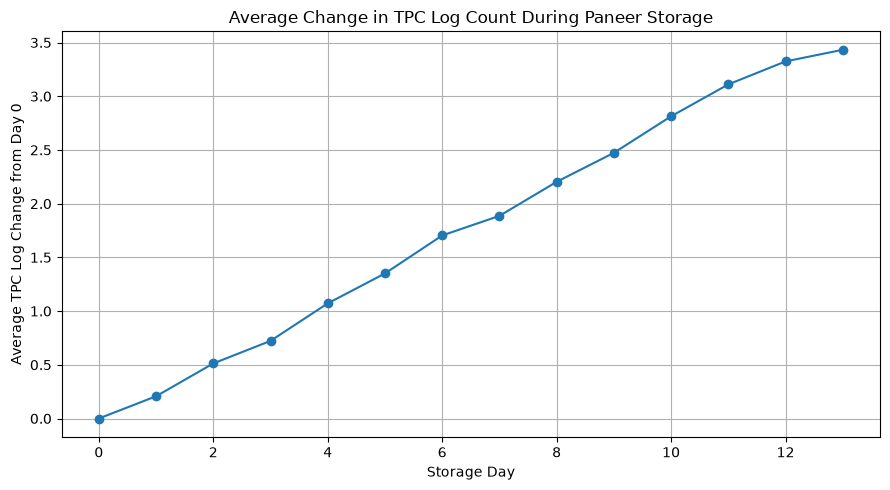

Correlation matrix:


,Day,TPC_Log_Change,pH_Change_From_Baseline,Moisture_Change_From_Baseline,TPC_Growth_Ratio
Day,1.00,0.99,-0.94,-0.93,0.18
TPC_Log_Change,0.99,1.00,-0.94,-0.91,0.24
pH_Change_From_Baseline,-0.94,-0.94,1.00,0.82,-0.23
Moisture_Change_From_Baseline,-0.93,-0.91,0.82,1.00,-0.13
TPC_Growth_Ratio,0.18,0.24,-0.23,-0.13,1.00


Final dataset shape: (70, 33)
Total missing values in engineered features: 0


In [5]:
# WEEK 3 - STEP 2: EVALUATE ENGINEERED FEATURES

import matplotlib.pyplot as plt

# 1. Average TPC growth over storage days
daily_tpc = (
    engineered_data.groupby("Day", observed=True)
    .agg(
        Average_TPC_Log_Change=("TPC_Log_Change", "mean"),
        Average_TPC_Growth_Ratio=("TPC_Growth_Ratio", "mean"),
        Average_pH_Change=("pH_Change_From_Baseline", "mean"),
        Average_Moisture_Change=("Moisture_Change_From_Baseline", "mean")
    )
    .reset_index()
)

print("Daily feature trends:")
display(daily_tpc.round(3))


# 2. Plot TPC log change over storage days

plt.figure(figsize=(9, 5))
plt.plot(
    daily_tpc["Day"],
    daily_tpc["Average_TPC_Log_Change"],
    marker="o"
)
plt.title("Average Change in TPC Log Count During Paneer Storage")
plt.xlabel("Storage Day")
plt.ylabel("Average TPC Log Change from Day 0")
plt.grid(True)
plt.tight_layout()
plt.show()


# 3. Correlation between selected numerical features

features_for_correlation = [
    "Day",
    "TPC_Log_Change",
    "pH_Change_From_Baseline",
    "Moisture_Change_From_Baseline",
    "TPC_Growth_Ratio"
]

correlation_matrix = engineered_data[
    features_for_correlation
].corr(numeric_only=True)

print("Correlation matrix:")
display(correlation_matrix.round(2))


# 4. Final dataset validation

print("Final dataset shape:", engineered_data.shape)
print(
    "Total missing values in engineered features:",
    engineered_data[
        [
            "Storage_Phase",
            "Baseline_TPC_Log10",
            "Baseline_pH",
            "Baseline_Moisture_Percent",
            "TPC_Log_Change",
            "pH_Change_From_Baseline",
            "Moisture_Change_From_Baseline",
            "Baseline_TPC_Count",
            "TPC_Growth_Ratio"
        ]
    ].isnull().sum().sum()
)

In [6]:
# WEEK 3 - STEP 3: SAVE FINAL OUTPUTS

from pathlib import Path
import pandas as pd

output_folder = Path("../data/processed")
output_folder.mkdir(parents=True, exist_ok=True)

# Save complete engineered dataset
engineered_data.to_csv(
    output_folder / "paneer_feature_engineered.csv",
    index=False
)

# Create a summary of the engineered features
feature_summary = pd.DataFrame({
    "Feature": [
        "Storage_Phase",
        "Baseline_TPC_Log10",
        "Baseline_pH",
        "Baseline_Moisture_Percent",
        "TPC_Log_Change",
        "pH_Change_From_Baseline",
        "Moisture_Change_From_Baseline",
        "Baseline_TPC_Count",
        "TPC_Growth_Ratio"
    ],
    "Purpose": [
        "Groups observations into early, middle, and late storage phases",
        "Records each replicate's initial TPC log value",
        "Records each replicate's initial pH",
        "Records each replicate's initial moisture percentage",
        "Measures change in TPC log count from baseline",
        "Measures pH change from baseline",
        "Measures moisture change from baseline",
        "Records each replicate's initial TPC count",
        "Measures current TPC count relative to baseline"
    ]
})

feature_summary.to_csv(
    output_folder / "paneer_feature_summary.csv",
    index=False
)

print("Feature-engineered dataset saved successfully.")
print("Feature summary saved successfully.")
print("Dataset shape:", engineered_data.shape)
print("New feature count:", len(feature_summary))
print("Missing values in new features:",
      engineered_data[feature_summary["Feature"]]
      .isnull().sum().sum())

Feature-engineered dataset saved successfully.
Feature summary saved successfully.
Dataset shape: (70, 33)
New feature count: 9
Missing values in new features: 0
